# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Naufal Atmaja Faadihilah
- **Email:** ds183b6y1343@student.devacademy.id
- **ID Dicoding:** ds183b6y1343

## Menentukan Pertanyaan Bisnis

**Latar belakang.** Dataset ini berisi riwayat penyewaan sepeda dari sistem *Capital Bikeshare* di Washington D.C. selama dua tahun (2011-2012), lengkap dengan informasi cuaca dan kalender. Bayangkan kita adalah tim analis dari operator bike sharing yang ingin menentukan jadwal redistribusi sepeda, strategi promosi, dan rencana ekspansi armada.

Pertanyaan bisnis disusun dengan kerangka SMART:

| Pertanyaan | Specific | Measurable | Action-Oriented | Time-bound |
|---|---|---|---|---|
| 1 | Pola jam puncak penyewaan, hari kerja vs akhir pekan/libur | Rata-rata penyewaan per jam | Menentukan jam redistribusi & penempatan armada | 2011-2012 |
| 2 | Pengaruh kondisi cuaca dan musim | Rata-rata penyewaan harian dan persentase selisihnya | Menyiapkan promosi/penyesuaian armada saat cuaca & musim kurang mendukung | 2011-2012 |
| 3 | Pertumbuhan penyewaan antar tahun per tipe pengguna | Total penyewaan bulanan dan persentase pertumbuhan 2012 vs 2011 | Menentukan segmen yang diprioritaskan untuk ekspansi | 2011 vs 2012 |

- **Pertanyaan 1:** Pada jam berapa permintaan sepeda mencapai puncak di hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011-2012, dan berapa selisih rata-rata penyewaannya pada jam-jam tersebut?
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata penyewaan harian pada kondisi cuaca buruk dibandingkan cuaca cerah, dan musim apa yang memiliki rata-rata penyewaan harian terendah selama 2011-2012?
- **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan sepanjang 2012 dibandingkan 2011, dan apakah pertumbuhan tersebut lebih banyak didorong oleh pengguna *registered* atau *casual*?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# tampilan visualisasi dibuat konsisten di seluruh notebook
BIRU, ORANYE, ABU, GELAP = '#1F6FB2', '#E07B39', '#BFC5CC', '#333333'
sns.set_theme(style='white', font_scale=1.0)
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.titlelocation': 'left',
    'figure.dpi': 110,
})

## Data Wrangling

### Gathering Data

#### Memuat data harian (day.csv) dan data per jam (hour.csv)

In [2]:
day_df = pd.read_csv('data/day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df = pd.read_csv('data/hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print('Ukuran data harian   :', day_df.shape)
print('Ukuran data per jam  :', hour_df.shape)

Ukuran data harian   : (731, 16)
Ukuran data per jam  : (17379, 17)


**Insight:**
- Data harian berisi 731 baris (1 Januari 2011 - 31 Desember 2012) dan data per jam berisi 17.379 baris. Keduanya memiliki kolom yang sama, hanya data per jam punya tambahan kolom `hr`.
- Data per jam dipakai untuk melihat pola jam (Pertanyaan 1), sedangkan data harian dipakai untuk pengaruh cuaca/musim dan tren (Pertanyaan 2 dan 3).
- Nilai `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk normalisasi, dan kolom kategori masih berupa kode angka sehingga perlu diterjemahkan.

### Assessing Data

#### Memeriksa tipe data, nilai kosong, dan duplikasi

In [5]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [6]:
cek = pd.DataFrame({
    'dataset': ['day_df', 'hour_df'],
    'missing value': [day_df.isna().sum().sum(), hour_df.isna().sum().sum()],
    'baris duplikat': [day_df.duplicated().sum(), hour_df.duplicated().sum()],
})
cek

,dataset,missing value,baris duplikat
0,day_df,0,0
1,hour_df,0,0


#### Memeriksa nilai yang tidak wajar

In [7]:
hour_df[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe().round(3)

,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000,17379.000
mean,0.497,0.476,0.627,0.190,35.676,153.787,189.463
std,0.193,0.172,0.193,0.122,49.305,151.357,181.388
min,0.020,0.000,0.000,0.000,0.000,0.000,1.000
25%,0.340,0.333,0.480,0.104,4.000,34.000,40.000
50%,0.500,0.485,0.630,0.194,17.000,115.000,142.000
75%,0.660,0.621,0.780,0.254,48.000,220.000,281.000
max,1.000,1.000,1.000,0.851,367.000,886.000,977.000


In [8]:
# kelembapan bernilai 0 secara fisik tidak masuk akal
print('Baris hum = 0 (per jam):', (hour_df['hum'] == 0).sum())
print(hour_df.loc[hour_df['hum'] == 0, 'dteday'].value_counts())
print()
print('Baris windspeed = 0 (per jam):', (hour_df['windspeed'] == 0).sum(),
      f"({(hour_df['windspeed'] == 0).mean():.1%})")

Baris hum = 0 (per jam): 22
dteday
2011-03-10    22
Name: count, dtype: int64

Baris windspeed = 0 (per jam): 2180 (12.5%)


#### Memeriksa kelengkapan jam dan konsistensi antar dataset

In [9]:
jam_seharusnya = 731 * 24
print('Jam seharusnya :', jam_seharusnya)
print('Jam tercatat   :', len(hour_df))
print('Jam hilang     :', jam_seharusnya - len(hour_df))

# apakah total per jam sama dengan angka di data harian?
total_per_hari = hour_df.groupby('dteday')['cnt'].sum()
selisih = (total_per_hari - day_df.set_index('dteday')['cnt']).abs().sum()
print('Selisih total penyewaan data per jam vs harian:', selisih)

print()
print('Distribusi weathersit (per jam):')
print(hour_df['weathersit'].value_counts().sort_index())

Jam seharusnya : 17544
Jam tercatat   : 17379
Jam hilang     : 165
Selisih total penyewaan data per jam vs harian: 0

Distribusi weathersit (per jam):
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


**Steps to Take:**
- Ubah dteday menjadi tipe *datetime*.
- Tangani kelembapan bernilai 0 pada 2011-03-10 sebagai data tidak valid, lalu isi dengan rata-rata kelembapan hari sebelum dan sesudahnya.
- Terjemahkan kode kategori (season, yr, weekday, workingday, weathersit) menjadi label yang mudah dibaca.
- Kembalikan temp, atemp, hum, dan windspeed ke satuan aslinya (denormalisasi).
- Nilai windspeed = 0 dibiarkan apa adanya, tetapi dicatat sebagai keterbatasan karena kemungkinan besar merupakan data yang tidak terukur.

**Insight:**
- Tidak ada *missing value* maupun baris duplikat pada kedua dataset.
- Ada satu anomali jelas: seluruh data kelembapan pada 2011-03-10 bernilai 0 (22 jam tercatat).
- Data per jam kehilangan 165 jam (17.379 dari 17.544 jam seharusnya). Ini wajar karena jam tanpa penyewaan tidak tercatat. Total per jam cocok dengan data harian (selisih 0), sehingga kedua dataset konsisten.
- Cuaca ekstrem (weathersit = 4) hanya muncul 3 kali, dan 0 kali di data harian. Kategori ini terlalu sedikit untuk disimpulkan.
- Sekitar 12,5% baris memiliki windspeed = 0, sehingga variabel kecepatan angin kurang dapat diandalkan dan tidak dijadikan dasar kesimpulan.

### Cleaning Data

#### Mengubah tipe data tanggal dan memperbaiki kelembapan yang tidak valid

In [10]:
for df in (day_df, hour_df):
    df['dteday'] = pd.to_datetime(df['dteday'])

# kelembapan 2011-03-10 -> rata-rata hari sebelum & sesudahnya
hari_tetangga = pd.to_datetime(['2011-03-09', '2011-03-11'])
hum_pengganti = hour_df.loc[hour_df['dteday'].isin(hari_tetangga), 'hum'].mean()

for df in (day_df, hour_df):
    df.loc[df['hum'] == 0, 'hum'] = hum_pengganti

print('Nilai pengganti kelembapan:', round(hum_pengganti, 3))
print('Sisa hum = 0 -> day:', (day_df['hum'] == 0).sum(), '| hour:', (hour_df['hum'] == 0).sum())

Nilai pengganti kelembapan: 0.714
Sisa hum = 0 -> day: 0 | hour: 0


#### Menerjemahkan kode kategori dan mengembalikan satuan asli

In [11]:
nama_musim = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
nama_hari = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
nama_cuaca = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Cuaca Ekstrem'}
nama_tipe_hari = {1: 'Hari Kerja', 0: 'Akhir Pekan/Libur'}

for df in (day_df, hour_df):
    df['season_label'] = df['season'].map(nama_musim)
    df['year'] = df['yr'].map({0: 2011, 1: 2012})
    df['month_label'] = df['dteday'].dt.strftime('%b')
    df['weekday_label'] = df['weekday'].map(nama_hari)
    df['day_type'] = df['workingday'].map(nama_tipe_hari)
    df['weather_label'] = df['weathersit'].map(nama_cuaca)

    # denormalisasi sesuai keterangan dataset
    df['temp_c'] = (df['temp'] * 41).round(1)
    df['atemp_c'] = (df['atemp'] * 50).round(1)
    df['hum_pct'] = (df['hum'] * 100).round(1)
    df['wind_kmh'] = (df['windspeed'] * 67).round(1)

hour_df[['dteday', 'hr', 'season_label', 'day_type', 'weather_label', 'temp_c', 'hum_pct', 'cnt']].head()

,dteday,hr,season_label,day_type,weather_label,temp_c,hum_pct,cnt
0,2011-01-01,0,Spring,Akhir Pekan/Libur,Cerah,9.8,81.0,16
1,2011-01-01,1,Spring,Akhir Pekan/Libur,Cerah,9.0,80.0,40
2,2011-01-01,2,Spring,Akhir Pekan/Libur,Cerah,9.0,80.0,32
3,2011-01-01,3,Spring,Akhir Pekan/Libur,Cerah,9.8,75.0,13
4,2011-01-01,4,Spring,Akhir Pekan/Libur,Cerah,9.8,75.0,1


In [12]:
# pastikan hasil cleaning sudah sesuai
print(hour_df['weather_label'].isna().sum(), 'label cuaca kosong')
print(hour_df[['temp_c', 'hum_pct', 'wind_kmh']].describe().loc[['min', 'max']])

0 label cuaca kosong
     temp_c  hum_pct  wind_kmh
min     0.8      8.0       0.0
max    41.0    100.0      57.0


**Insight:**
- Setelah cleaning, suhu berada pada rentang 0,8-41 derajat Celsius dan kelembapan pada rentang yang wajar, sehingga data siap dianalisis.
- Label yang terbaca manusia (musim, jenis hari, cuaca) membuat tabel dan grafik berikutnya langsung dapat dibaca tanpa membuka kamus data.

## Exploratory Data Analysis (EDA)

### Gambaran umum penyewaan

In [13]:
day_df[['cnt', 'casual', 'registered']].describe().round(1)

,cnt,casual,registered
count,731.0,731.0,731.0
mean,4504.3,848.2,3656.2
std,1937.2,686.6,1560.3
min,22.0,2.0,20.0
25%,3152.0,315.5,2497.0
50%,4548.0,713.0,3662.0
75%,5956.0,1096.0,4776.5
max,8714.0,3410.0,6946.0


In [14]:
porsi = day_df[['casual', 'registered']].sum() / day_df['cnt'].sum()
print('Porsi total penyewaan berdasarkan tipe pengguna:')
print((porsi * 100).round(1).astype(str) + '%')

Porsi total penyewaan berdasarkan tipe pengguna:
casual        18.8%
registered    81.2%
dtype: str


### Penyewaan berdasarkan musim, cuaca, dan jenis hari

In [15]:
pd.DataFrame({
    'rata-rata harian per musim': day_df.groupby('season_label')['cnt'].mean(),
}).round(0).T

season_label,Fall,Spring,Summer,Winter
rata-rata harian per musim,5644.0,2604.0,4992.0,4728.0


In [16]:
day_df.groupby('weather_label')['cnt'].agg(['count', 'mean']).round(0).rename(
    columns={'count': 'jumlah hari', 'mean': 'rata-rata penyewaan harian'})

,jumlah hari,rata-rata penyewaan harian
weather_label,,
Berkabut/Berawan,247,4036.0
Cerah,463,4877.0
Hujan/Salju Ringan,21,1803.0


In [17]:
day_df.groupby('day_type')[['casual', 'registered']].mean().round(0)

,casual,registered
day_type,,
Akhir Pekan/Libur,1371.0,2959.0
Hari Kerja,607.0,3978.0


### Hubungan antara kondisi lingkungan dan penyewaan

In [18]:
day_df[['cnt', 'temp_c', 'hum_pct', 'wind_kmh']].corr().round(2)

,cnt,temp_c,hum_pct,wind_kmh
cnt,1.00,0.63,-0.12,-0.23
temp_c,0.63,1.00,0.12,-0.16
hum_pct,-0.12,0.12,1.00,-0.25
wind_kmh,-0.23,-0.16,-0.25,1.00


**Insight:**
- Rata-rata penyewaan harian sekitar 4.500 sepeda dengan sebaran yang cukup lebar (22 sampai 8.714). Pengguna *registered* menyumbang sekitar 81% dari seluruh penyewaan.
- Rata-rata penyewaan terendah ada pada musim Spring, jauh di bawah musim lainnya. Rata-rata tertinggi ada pada musim Fall.
- Hari hujan/salju ringan hanya berjumlah 21 hari, tetapi rata-ratanya sangat rendah dibanding hari cerah.
- Pengguna *casual* jauh lebih aktif di akhir pekan/libur, sedangkan pengguna *registered* lebih aktif di hari kerja. Ini mengindikasikan perbedaan tujuan penggunaan (rekreasi vs komuter).
- Suhu memiliki korelasi positif yang cukup kuat dengan penyewaan harian (sekitar 0,63). Kecepatan angin (sekitar -0,23) dan kelembapan (sekitar -0,12) berkorelasi negatif tetapi lemah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa permintaan sepeda mencapai puncak di hari kerja dibandingkan akhir pekan/hari libur?

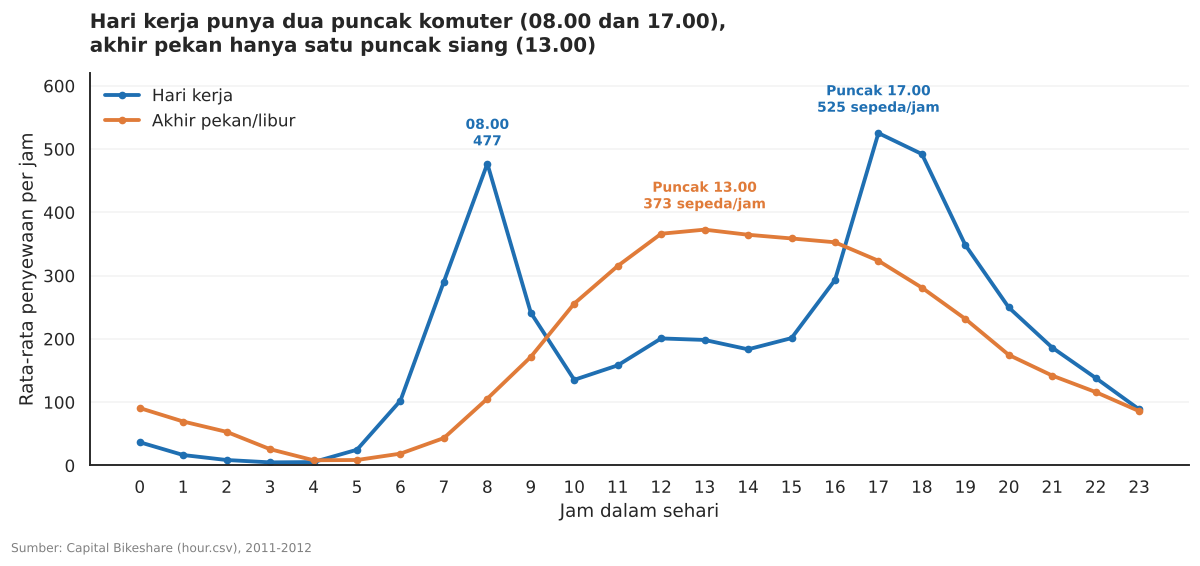

In [19]:
pola_jam = hour_df.groupby(['hr', 'day_type'])['cnt'].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(pola_jam.index, pola_jam['Hari Kerja'], color=BIRU, lw=2.5, marker='o', ms=4, label='Hari kerja')
ax.plot(pola_jam.index, pola_jam['Akhir Pekan/Libur'], color=ORANYE, lw=2.5, marker='o', ms=4, label='Akhir pekan/libur')

# tandai puncak masing-masing pola
for kolom, warna, geser in [('Hari Kerja', BIRU, (0, 14)), ('Akhir Pekan/Libur', ORANYE, (0, 14))]:
    jam_puncak = pola_jam[kolom].idxmax()
    nilai = pola_jam[kolom].max()
    ax.annotate(f'Puncak {jam_puncak:02d}.00\n{nilai:.0f} sepeda/jam', (jam_puncak, nilai),
                textcoords='offset points', xytext=geser, ha='center', color=warna, fontsize=9, fontweight='bold')
jam_pagi = pola_jam['Hari Kerja'].loc[8]
ax.annotate(f'08.00\n{jam_pagi:.0f}', (8, jam_pagi), textcoords='offset points',
            xytext=(0, 12), ha='center', color=BIRU, fontsize=9, fontweight='bold')

ax.set_xticks(range(0, 24))
ax.set_xlabel('Jam dalam sehari')
ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_ylim(0, 620)
ax.set_title('Hari kerja punya dua puncak komuter (08.00 dan 17.00),\nakhir pekan hanya satu puncak siang (13.00)', pad=14)
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='y', alpha=0.25)
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (hour.csv), 2011-2012', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

In [20]:
puncak = pola_jam.loc[[8, 13, 17]].round(0)
puncak['selisih (kerja - libur)'] = puncak['Hari Kerja'] - puncak['Akhir Pekan/Libur']
puncak

day_type,Akhir Pekan/Libur,Hari Kerja,selisih (kerja - libur)
hr,,,
8,106.0,477.0,371.0
13,373.0,198.0,-175.0
17,324.0,525.0,201.0


**Insight Pertanyaan 1:**
- Pada hari kerja terdapat dua puncak jam sibuk: sekitar 08.00 (477 sepeda/jam) dan 17.00 (525 sepeda/jam). Pola ini khas perjalanan berangkat dan pulang kerja.
- Pada akhir pekan/libur permintaan naik pelan-pelan dan mencapai puncak sekitar 13.00 (sekitar 373 sepeda/jam), tanpa lonjakan pagi.
- Pada pukul 08.00, hari kerja sekitar 4,5 kali lebih tinggi dari akhir pekan (477 vs 106). Sebaliknya, pada pukul 13.00 akhir pekan unggul hampir dua kali lipat (373 vs 198).

### Pertanyaan 2: Seberapa besar penurunan penyewaan saat cuaca buruk, dan musim mana yang terendah?

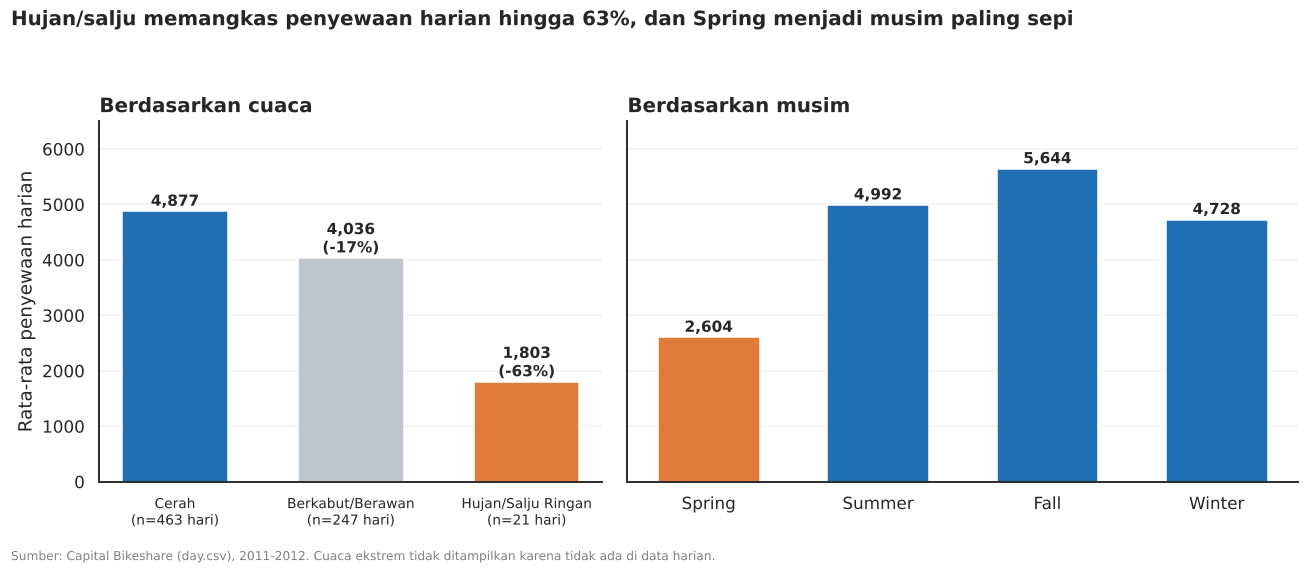

In [21]:
urutan_cuaca = ['Cerah', 'Berkabut/Berawan', 'Hujan/Salju Ringan']
urutan_musim = ['Spring', 'Summer', 'Fall', 'Winter']

rata_cuaca = day_df.groupby('weather_label')['cnt'].agg(['mean', 'count']).loc[urutan_cuaca]
rata_musim = day_df.groupby('season_label')['cnt'].mean().loc[urutan_musim]
rata_cuaca['selisih'] = rata_cuaca['mean'] / rata_cuaca.loc['Cerah', 'mean'] - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, gridspec_kw={'width_ratios': [3, 4]})

# panel kiri: cuaca
warna_cuaca = [BIRU, ABU, ORANYE]
axes[0].bar(urutan_cuaca, rata_cuaca['mean'], color=warna_cuaca, width=0.6)
for i, (nama, baris) in enumerate(rata_cuaca.iterrows()):
    teks = f"{baris['mean']:,.0f}"
    if nama != 'Cerah':
        teks += f"\n({baris['selisih']:.0%})"
    axes[0].text(i, baris['mean'] + 100, teks, ha='center', fontsize=10, fontweight='bold')
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([f"{n}\n(n={int(c)} hari)" for n, c in zip(urutan_cuaca, rata_cuaca['count'])], fontsize=9)
axes[0].set_title('Berdasarkan cuaca')
axes[0].set_ylabel('Rata-rata penyewaan harian')

# panel kanan: musim (Spring disorot karena terendah)
warna_musim = [ORANYE if m == rata_musim.idxmin() else BIRU for m in urutan_musim]
axes[1].bar(urutan_musim, rata_musim, color=warna_musim, width=0.6)
for i, nilai in enumerate(rata_musim):
    axes[1].text(i, nilai + 100, f'{nilai:,.0f}', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Berdasarkan musim')

for ax in axes:
    ax.set_ylim(0, 6500)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Hujan/salju memangkas penyewaan harian hingga 63%, dan Spring menjadi musim paling sepi',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (day.csv), 2011-2012. Cuaca ekstrem tidak ditampilkan karena tidak ada di data harian.',
         fontsize=8, color='gray')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Insight Pertanyaan 2:**
- Dibanding hari cerah (sekitar 4.877 sepeda/hari), hari berkabut/berawan turun sekitar 17% dan hari hujan/salju ringan turun sekitar 63% (sekitar 1.803 sepeda/hari).
- Catatan integritas: kelompok hujan/salju ringan hanya terdiri dari 21 hari, jadi angkanya perlu dibaca sebagai indikasi, bukan angka pasti.
- Musim Spring memiliki rata-rata harian terendah (sekitar 2.604), sedangkan Fall tertinggi (sekitar 5.644). Perlu diingat bahwa 2011 dan 2012 berbeda jauh sehingga sebagian efek musim bercampur dengan efek pertumbuhan (dibahas pada Pertanyaan 3).

### Pertanyaan 3: Bagaimana pertumbuhan penyewaan 2012 dibanding 2011, dan siapa pendorongnya?

In [22]:
urutan_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

bulanan = (day_df.groupby(['year', 'month_label'])['cnt'].sum()
           .unstack(0).loc[urutan_bulan])

per_tahun = day_df.groupby('year')[['casual', 'registered', 'cnt']].sum()
pertumbuhan = (per_tahun.loc[2012] / per_tahun.loc[2011] - 1) * 100
pertumbuhan.round(1)

casual        50.8
registered    68.4
cnt           64.9
dtype: float64

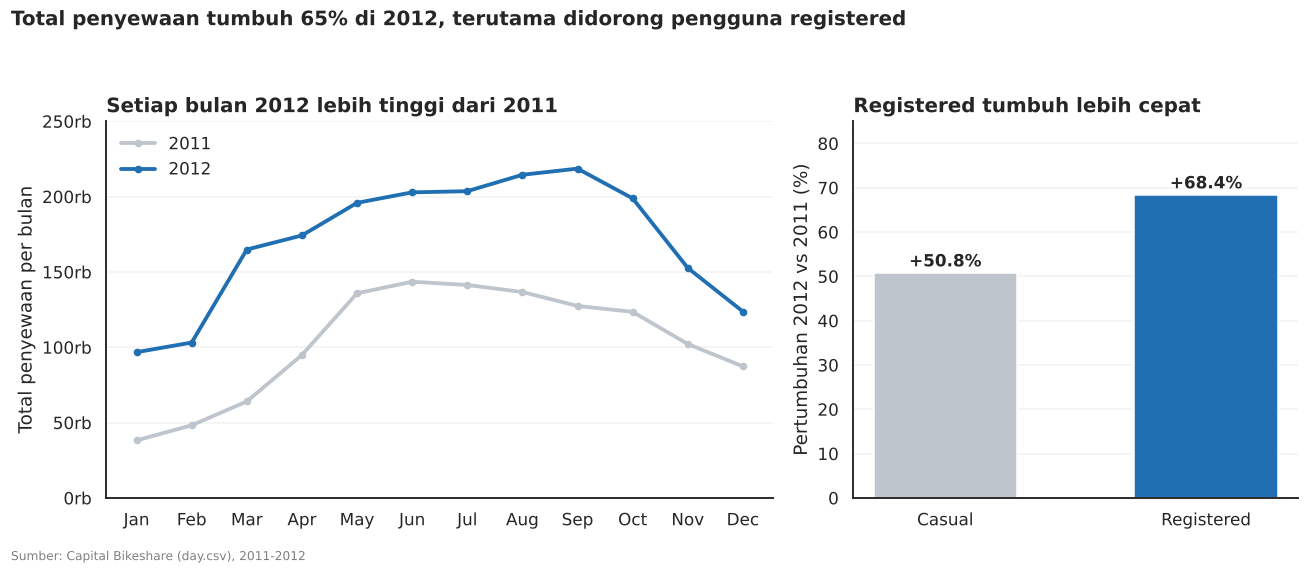

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [3, 2]})

# panel kiri: tren bulanan
axes[0].plot(urutan_bulan, bulanan[2011], color=ABU, lw=2.5, marker='o', ms=4, label='2011')
axes[0].plot(urutan_bulan, bulanan[2012], color=BIRU, lw=2.5, marker='o', ms=4, label='2012')
axes[0].set_ylim(0, 250000)
axes[0].set_ylabel('Total penyewaan per bulan')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}rb'))
axes[0].legend(frameon=False, loc='upper left')
axes[0].grid(axis='y', alpha=0.25)
axes[0].set_title('Setiap bulan 2012 lebih tinggi dari 2011')

# panel kanan: pertumbuhan per tipe pengguna
tipe = ['casual', 'registered']
axes[1].bar(['Casual', 'Registered'], [pertumbuhan[t] for t in tipe], color=[ABU, BIRU], width=0.55)
for i, t in enumerate(tipe):
    axes[1].text(i, pertumbuhan[t] + 1.5, f'+{pertumbuhan[t]:.1f}%', ha='center', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 85)
axes[1].set_ylabel('Pertumbuhan 2012 vs 2011 (%)')
axes[1].grid(axis='y', alpha=0.25)
axes[1].set_title('Registered tumbuh lebih cepat')

fig.suptitle(f'Total penyewaan tumbuh {pertumbuhan["cnt"]:.0f}% di 2012, terutama didorong pengguna registered',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (day.csv), 2011-2012', fontsize=8, color='gray')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Insight Pertanyaan 3:**
- Total penyewaan naik sekitar 65%, dari sekitar 1,24 juta (2011) menjadi sekitar 2,05 juta (2012). Seluruh bulan di 2012 lebih tinggi dari bulan yang sama di 2011.
- Pengguna *registered* tumbuh sekitar 68%, lebih cepat dari *casual* yang tumbuh sekitar 51%. Pertumbuhan 2012 bertumpu pada basis pelanggan tetap.
- Pertumbuhan terbesar terjadi di awal tahun (Januari-Maret naik lebih dari 100%), saat 2011 masih merupakan fase awal sistem. Perbedaan musiman antar bulan karenanya perlu dibaca dengan hati-hati.

## Analisis Lanjutan

Teknik analisis lanjutan yang dipilih adalah **Clustering tanpa algoritma machine learning**, yaitu *manual grouping* dan *binning*. Alasannya:

- **RFM Analysis tidak dipakai** karena dataset tidak memiliki identitas pelanggan (hanya agregat penyewaan per jam/hari), sehingga recency, frequency, dan monetary per pelanggan tidak dapat dihitung.
- **Geospatial Analysis tidak dipakai** karena dataset tidak memuat koordinat atau lokasi stasiun.
- **Manual grouping dan binning relevan** karena dataset kaya akan variabel kontinu (jam, suhu, jumlah penyewaan, proporsi pengguna) yang dapat dikelompokkan berdasarkan aturan bisnis agar mudah ditindaklanjuti.

Empat pengelompokan yang dilakukan:
1. **Binning jam menjadi waktu dalam sehari** (Dini Hari, Pagi, Siang, Sore, Malam) untuk melihat pola jam sibuk secara ringkas.
2. **Binning suhu harian** menjadi Dingin, Sejuk, Hangat, dan Panas untuk mengukur sensitivitas permintaan terhadap suhu.
3. **Manual grouping tingkat permintaan harian** (Rendah < 3.000, Sedang 3.000-6.000, Tinggi > 6.000 sepeda/hari) untuk melihat sebaran hari sepi dan ramai tiap musim.
4. **Manual grouping karakter pengguna** berdasarkan porsi pengguna *casual* pada hari tersebut: Komuter (< 15%), Campuran (15-30%), dan Rekreasi (> 30%).

### 1. Binning jam menjadi waktu dalam sehari

In [24]:
def kelompok_waktu(jam):
    if jam <= 5:
        return 'Dini Hari (00-05)'
    elif jam <= 9:
        return 'Pagi (06-09)'
    elif jam <= 15:
        return 'Siang (10-15)'
    elif jam <= 19:
        return 'Sore (16-19)'
    return 'Malam (20-23)'

hour_df['time_of_day'] = hour_df['hr'].apply(kelompok_waktu)

urutan_waktu = ['Dini Hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)', 'Sore (16-19)', 'Malam (20-23)']
waktu = hour_df.pivot_table(index='time_of_day', columns='day_type', values='cnt', aggfunc='mean').loc[urutan_waktu]
waktu.round(0)

day_type,Akhir Pekan/Libur,Hari Kerja
time_of_day,,
Dini Hari (00-05),43.0,16.0
Pagi (06-09),85.0,278.0
Siang (10-15),339.0,180.0
Sore (16-19),297.0,415.0
Malam (20-23),130.0,166.0


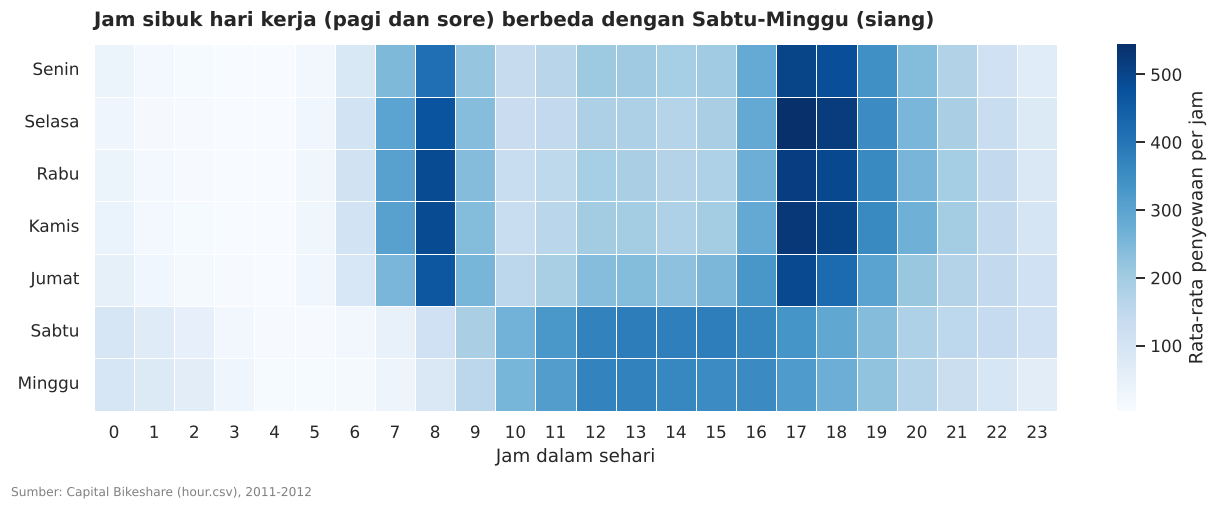

In [25]:
urutan_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
heat = hour_df.pivot_table(index='weekday_label', columns='hr', values='cnt', aggfunc='mean').loc[urutan_hari]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, cmap='Blues', linewidths=0.4, linecolor='white', cbar_kws={'label': 'Rata-rata penyewaan per jam'}, ax=ax)
ax.set_xlabel('Jam dalam sehari')
ax.set_ylabel('')
ax.set_title('Jam sibuk hari kerja (pagi dan sore) berbeda dengan Sabtu-Minggu (siang)', pad=12)
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (hour.csv), 2011-2012', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

**Insight:**
- Waktu **Sore (16-19)** adalah kelompok dengan rata-rata penyewaan tertinggi (sekitar 378 sepeda/jam), disusul Siang dan Pagi. Dini hari paling sepi (sekitar 25 sepeda/jam).
- Peta panas memperlihatkan Senin-Jumat memiliki dua blok gelap (pagi dan sore), sedangkan Sabtu-Minggu hanya satu blok pada siang hari. Hal ini memperkuat temuan Pertanyaan 1.
- Dini hari (00-05) hampir tidak ada permintaan sehingga cocok sebagai jendela waktu redistribusi dan pemeliharaan sepeda.

### 2. Binning suhu harian

In [26]:
batas_suhu = [0, 10, 20, 30, 41]
label_suhu = ['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (>30°C)']
day_df['temp_group'] = pd.cut(day_df['temp_c'], bins=batas_suhu, labels=label_suhu, include_lowest=True)

suhu = day_df.groupby('temp_group', observed=True)['cnt'].agg(['count', 'mean']).round(0)
suhu.columns = ['jumlah hari', 'rata-rata penyewaan harian']
suhu

,jumlah hari,rata-rata penyewaan harian
temp_group,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


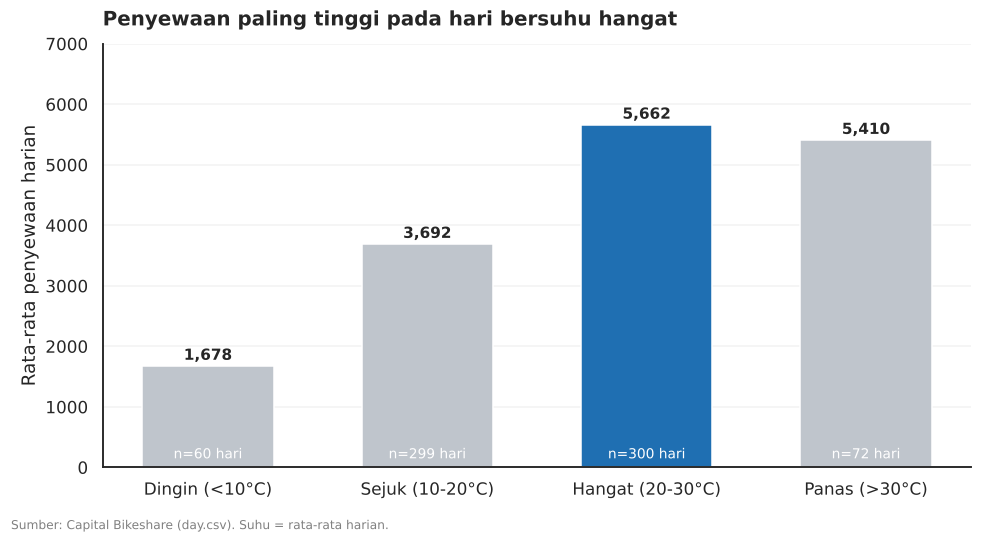

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.8))
nilai = suhu['rata-rata penyewaan harian']
warna = [BIRU if v == nilai.max() else ABU for v in nilai]
ax.bar(suhu.index, nilai, color=warna, width=0.6)
for i, (v, n) in enumerate(zip(nilai, suhu['jumlah hari'])):
    ax.text(i, v + 100, f'{v:,.0f}', ha='center', fontsize=10, fontweight='bold')
    ax.text(i, 150, f'n={int(n)} hari', ha='center', fontsize=9, color='white')
ax.set_ylim(0, 7000)
ax.set_ylabel('Rata-rata penyewaan harian')
ax.set_title('Penyewaan paling tinggi pada hari bersuhu hangat', pad=12)
ax.grid(axis='y', alpha=0.25)
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (day.csv). Suhu = rata-rata harian.', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

**Insight:**
- Permintaan meningkat seiring suhu dari kelompok Dingin sampai Hangat. Hari dingin (< 10°C) rata-rata hanya sekitar sepertiga dari hari hangat.
- Kelompok Panas (> 30°C) tidak lebih tinggi dari kelompok Hangat, sehingga hubungan suhu dan penyewaan tidak sepenuhnya linear. Kelompok Panas juga memiliki jumlah hari yang sedikit, jadi perlu dibaca hati-hati.

### 3. Manual grouping tingkat permintaan harian

In [28]:
day_df['demand_level'] = pd.cut(day_df['cnt'], bins=[0, 3000, 6000, day_df['cnt'].max()],
                                labels=['Rendah', 'Sedang', 'Tinggi'])

komposisi = pd.crosstab(day_df['season_label'], day_df['demand_level'], normalize='index').loc[urutan_musim] * 100
komposisi.round(1)

demand_level,Rendah,Sedang,Tinggi
season_label,,,
Spring,64.6,32.6,2.8
Summer,13.6,52.7,33.7
Fall,2.1,56.4,41.5
Winter,14.6,65.7,19.7


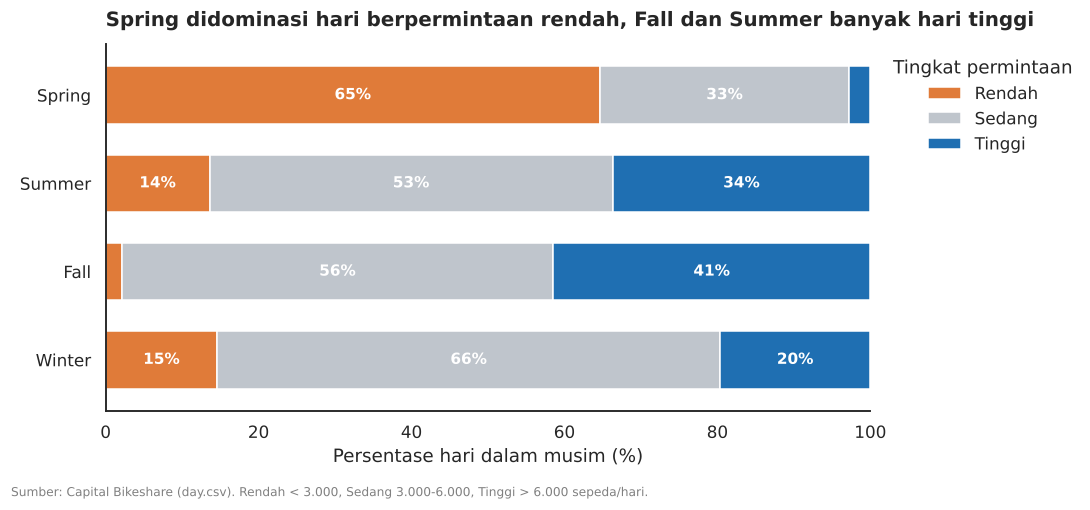

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
komposisi.plot(kind='barh', stacked=True, ax=ax, color=[ORANYE, ABU, BIRU], width=0.65)
ax.invert_yaxis()
for container in ax.containers:
    labels = [f'{v:.0f}%' if v >= 6 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', color='white', fontsize=10, fontweight='bold')
ax.set_xlim(0, 100)
ax.set_xlabel('Persentase hari dalam musim (%)')
ax.set_ylabel('')
ax.set_title('Spring didominasi hari berpermintaan rendah, Fall dan Summer banyak hari tinggi', pad=12)
ax.legend(title='Tingkat permintaan', frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (day.csv). Rendah < 3.000, Sedang 3.000-6.000, Tinggi > 6.000 sepeda/hari.', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

**Insight:**
- Sekitar 65% hari pada musim Spring masuk kategori permintaan Rendah, sedangkan di Fall hanya sekitar 2%.
- Fall dan Summer memiliki proporsi hari bermintaan Tinggi terbesar, sehingga armada perlu dioptimalkan penuh pada kedua musim ini. Pada Spring, jadwal pemeliharaan armada dapat dipusatkan.

### 4. Manual grouping karakter pengguna

In [30]:
day_df['casual_share'] = day_df['casual'] / day_df['cnt']
day_df['user_profile'] = pd.cut(day_df['casual_share'], bins=[0, 0.15, 0.30, 1.0],
                                labels=['Komuter (<15% casual)', 'Campuran (15-30%)', 'Rekreasi (>30% casual)'])

profil = pd.crosstab(day_df['day_type'], day_df['user_profile'])
profil

user_profile,Komuter (<15% casual),Campuran (15-30%),Rekreasi (>30% casual)
day_type,,,
Akhir Pekan/Libur,29,71,131
Hari Kerja,339,159,2


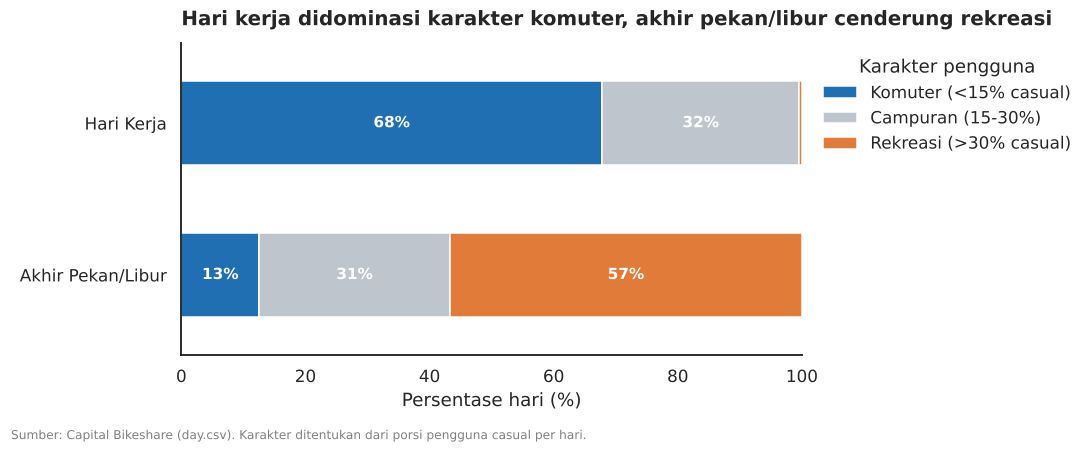

In [31]:
profil_pct = profil.div(profil.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4))
profil_pct.plot(kind='barh', stacked=True, ax=ax, color=[BIRU, ABU, ORANYE], width=0.55)
for container in ax.containers:
    labels = [f'{v:.0f}%' if v >= 6 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', color='white', fontsize=10, fontweight='bold')
ax.set_xlim(0, 100)
ax.set_xlabel('Persentase hari (%)')
ax.set_ylabel('')
ax.set_title('Hari kerja didominasi karakter komuter, akhir pekan/libur cenderung rekreasi', pad=12)
ax.legend(title='Karakter pengguna', frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left')
fig.text(0.01, -0.02, 'Sumber: Capital Bikeshare (day.csv). Karakter ditentukan dari porsi pengguna casual per hari.', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

**Insight:**
- Sekitar 68% hari kerja berkarakter Komuter dan hampir tidak ada hari kerja yang berkarakter Rekreasi.
- Sebaliknya, sekitar 57% hari akhir pekan/libur berkarakter Rekreasi. Pengguna *casual* menjadi target yang tepat untuk promosi akhir pekan, sedangkan pengguna *registered* untuk layanan komuter.

#### Menyimpan data akhir untuk dashboard

In [32]:
# label cuaca harian (dari day.csv) ditambahkan ke data per jam agar dashboard konsisten dengan notebook
hour_df = hour_df.merge(day_df[['dteday', 'weather_label']].rename(columns={'weather_label': 'weather_day'}),
                        on='dteday', how='left')

hour_df.to_csv('dashboard/main_data.csv', index=False)
print('main_data.csv tersimpan:', hour_df.shape)

main_data.csv tersimpan: (17379, 29)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Permintaan di hari kerja memuncak dua kali, yaitu sekitar pukul 08.00 (477 sepeda/jam) dan 17.00 (525 sepeda/jam), mengikuti jam berangkat dan pulang kerja. Di akhir pekan/libur hanya ada satu puncak sekitar pukul 13.00 (sekitar 373 sepeda/jam). Pada pukul 08.00 hari kerja lebih tinggi sekitar 4,5 kali dibanding akhir pekan.
- **Conclusion pertanyaan 2:** Dibanding hari cerah, rata-rata penyewaan harian turun sekitar 17% saat berkabut/berawan dan sekitar 63% saat hujan/salju ringan (catatan: hanya 21 hari). Spring adalah musim dengan rata-rata harian terendah (sekitar 2.604 sepeda/hari), sedangkan Fall tertinggi (sekitar 5.644).
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh sekitar 65% dibanding 2011. Pengguna *registered* tumbuh lebih cepat (sekitar 68%) dibanding *casual* (sekitar 51%), sehingga pertumbuhan ditopang pelanggan tetap.

**Rekomendasi Action Item:**
- Lakukan redistribusi sepeda ke area perkantoran/stasiun sebelum pukul 07.00 dan sebelum pukul 16.00 pada hari kerja. Lakukan juga pemeliharaan armada pada dini hari (00.00-05.00) saat permintaan hampir nol.
- Di akhir pekan/libur, pindahkan ketersediaan sepeda ke area wisata/taman dengan puncak sekitar tengah hari.
- Siapkan promosi khusus (misalnya diskon atau paket harian) pada hari berkabut atau hujan ringan, serta gunakan Spring untuk pemeliharaan besar-besaran dan kampanye menarik pengguna baru.
- Prioritaskan program loyalitas dan paket langganan untuk pengguna *registered* karena menjadi motor pertumbuhan. Untuk pengguna *casual* (yang dominan saat akhir pekan), tawarkan promo akhir pekan untuk mendorong konversi menjadi anggota.
- Keterbatasan: data hanya mencakup satu kota selama dua tahun, sehingga temuan musiman bercampur dengan tren pertumbuhan, dan kelompok cuaca ekstrem terlalu sedikit untuk disimpulkan.